# Traffic Signal Timing Simulation Using Monte Carlo Method

Compare fixed and adaptive signals at a two-road intersection using synthetic traffic arrivals. The primary outcome is mean time from arrival to departure. No real traffic data or animation is used.

**Model:** One vehicle can arrive per road per second. Vehicles cross in first-in, first-out order, one every 3 green seconds. Each green phase is followed by a 3-second yellow phase with no departures. Fixed green time is 30 seconds; adaptive green time is 15–45 seconds based on the queue at the start of green. All arrivals are cleared before measuring the mean delay. The two controllers receive identical arrivals in each of 100 independent runs.

## 1. Setup and Parameters

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

np.random.seed(42)
RUNS = 100
DURATION = 900
PROBABILITIES = [0.16, 0.09]

## 2. Traffic Simulation

In [2]:
def simulate_traffic(arrivals, controller):
    queues = [[], []]
    waits = []
    road, remaining, elapsed = 0, 0, 0
    yellow = False

    for second in range(len(arrivals) + 1800):
        if second < len(arrivals):
            for lane in range(2):
                if arrivals[second, lane]:
                    queues[lane].append(second)

        if remaining == 0:
            if yellow:
                road, yellow = 1 - road, False
            remaining = 30 if controller == "fixed" else int(np.clip(15 + 2 * len(queues[road]), 15, 45))
            elapsed = 0

        if not yellow:
            elapsed += 1
            if elapsed % 3 == 0 and queues[road]:
                waits.append(second - queues[road].pop(0) + 1)

        remaining -= 1
        if remaining == 0 and not yellow:
            yellow, remaining = True, 3

        if second >= len(arrivals) - 1 and not any(queues):
            return np.mean(waits)

    raise RuntimeError("Queues did not clear.")

## 3. Monte Carlo Simulation

Uniform random numbers in [0, 1) are compared with arrival probabilities. Each run uses the same arrivals for both controllers. The 100 paired differences are the observations for the statistical test.

In [3]:
fixed_waits, adaptive_waits = [], []
for _ in range(RUNS):
    arrivals = np.random.rand(DURATION, 2) < PROBABILITIES
    fixed_waits.append(simulate_traffic(arrivals, "fixed"))
    adaptive_waits.append(simulate_traffic(arrivals, "adaptive"))

differences = np.array(fixed_waits) - np.array(adaptive_waits)
print(f"Fixed mean delay: {np.mean(fixed_waits):.2f} seconds")
print(f"Adaptive mean delay: {np.mean(adaptive_waits):.2f} seconds")
print(f"Mean reduction: {np.mean(differences):.2f} seconds")

Fixed mean delay: 45.44 seconds
Adaptive mean delay: 27.19 seconds
Mean reduction: 18.25 seconds


## 4. Statistical Analysis

H0: The population mean paired delay difference is zero.

H1: The population mean paired delay difference is not zero.

A one-sample t-test on the paired differences is equivalent to a paired t-test. The confidence interval estimates the mean difference (Fixed - Adaptive), in seconds.

In [4]:
alpha = 0.05
t_statistic, p_value = stats.ttest_1samp(differences, 0)
std_err = np.std(differences, ddof=1) / np.sqrt(RUNS)
ci = stats.t.interval(0.95, RUNS - 1, loc=np.mean(differences), scale=std_err)
print(f"t-Statistic: {t_statistic:.4f}")
print(f"p-Value: {p_value:.4g}")
print(f"95% Confidence Interval: [{ci[0]:.2f}, {ci[1]:.2f}] seconds")
if p_value < alpha:
    print("Reject H0: The mean delays differ significantly.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

t-Statistic: 12.7059
p-Value: 1.624e-22
95% Confidence Interval: [15.40, 21.10] seconds
Reject H0: The mean delays differ significantly.


## 5. Visualization (Member 4)

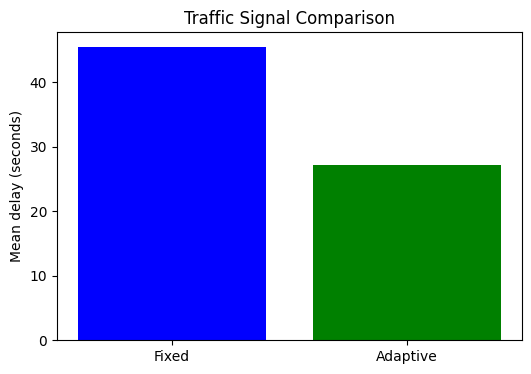

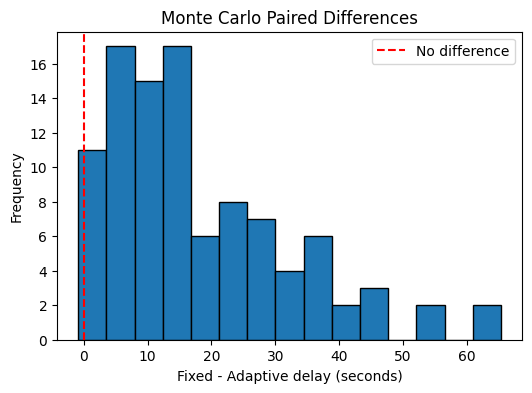

In [5]:
plt.figure(figsize=(6, 4))
plt.bar(["Fixed", "Adaptive"], [np.mean(fixed_waits), np.mean(adaptive_waits)], color=["blue", "green"])
plt.ylabel("Mean delay (seconds)")
plt.title("Traffic Signal Comparison")
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(differences, bins=15, edgecolor="black")
plt.axvline(0, color="red", linestyle="--", label="No difference")
plt.xlabel("Fixed - Adaptive delay (seconds)")
plt.ylabel("Frequency")
plt.title("Monte Carlo Paired Differences")
plt.legend()
plt.show()

## Conclusion and Limitations

A positive mean difference favors the adaptive signal in this model. The t-test and confidence interval quantify the evidence across the simulated runs, not across actual intersections. Arrival probabilities and service times are assumed. The model excludes turning vehicles, pedestrians, and detailed vehicle motion. It measures time until departure (including service), not stopped time alone.